In [62]:
from langgraph.graph import StateGraph ,START,END
from typing import TypedDict,Literal

In [63]:
class StudentSubject(TypedDict):
    math:int
    ml:int
    dp:int
    python:int
    sql:int
    attendance:int

    marks:str

    avg_sub:float
    avg_attendance:float

    average:float
    performance:str


In [64]:
def show_marks(state:StudentSubject):
    subjects=f'{state['math']}+{state["ml"]}+{state["dp"]}+{state["python"]}+{state["sql"]}'
    return {'marks':subjects}



In [65]:
def average_of_subject(state:StudentSubject):
    average_sub=(state['math']+state['ml']+state['dp']+state['python']+state['sql']/5)
    
    return{'avg_sub':average_sub}

In [66]:
def total_average(state:StudentSubject):
    average_of_student=(state['avg_sub']*0.8+state['avg_attendance']*0.2)
    return {'average':average_of_student}

In [67]:
graph=StateGraph(StudentSubject)

graph.add_node('show_marks',show_marks)
graph.add_node('total_average',total_average)

graph.add_edge(START,'show_marks')
graph.add_edge('show_marks','total_average')
graph.add_edge('total_average',END)



workflow=graph.compile()


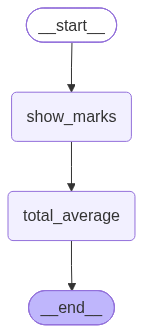

In [68]:
workflow

In [69]:
in_state={
        'math':70,
        'ml':80,
        'dp':90,
        'python':50,
        'sql':60,
        'attendance':85
}

In [70]:
workflow.invoke(in_state)

KeyError: 'avg_sub'